# 🟡 2. Core: Artificial Neural Networks & Iris Classification

### *Multi-Layer Perceptrons (MLP), Forward & Backpropagation Calculus, Solving XOR from Scratch, and Iris Multiclass Classification*

---

## 📌 Module Overview
1. **From Single-Layer to Multi-Layer Networks**: How hidden layers transform feature representations.
2. **Anatomy of a Neuron**: Synaptic weights, bias (threshold shift), linear combination, and non-linear activation.
3. **Universal Approximation Theorem**: Why depth yields exponential expressiveness over wide shallow networks.
4. **Forward & Backpropagation Calculus**: Step-by-step matrix equations and the chain rule.
5. **NumPy Implementation from Scratch**: A 2-Layer Neural Network solving XOR with decision surface visualization.
6. **Hands-On Iris Classification**: Contrasting a linear Perceptron vs. a Multi-Layer ANN with Softmax.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

SEED = 42
np.random.seed(SEED)
print("Environment initialized for ANN architecture exploration.")


Environment initialized for ANN architecture exploration.


## 1. 2-Layer Neural Network from Scratch in Pure NumPy
Here we implement a complete 2-Layer Neural Network (Input $\to$ Hidden $\to$ Output) with exact analytical gradients:
* **Forward Pass**:
  $$\mathbf{Z}^{[1]} = \mathbf{X} \mathbf{W}^{[1]} + \mathbf{b}^{[1]}, \quad \mathbf{A}^{[1]} = \tanh(\mathbf{Z}^{[1]})$$
  $$\mathbf{Z}^{[2]} = \mathbf{A}^{[1]} \mathbf{W}^{[2]} + \mathbf{b}^{[2]}, \quad \mathbf{A}^{[2]} = \sigma(\mathbf{Z}^{[2]})$$
* **Backpropagation**:
  $$d\mathbf{Z}^{[2]} = \mathbf{A}^{[2]} - \mathbf{Y}$$
  $$d\mathbf{W}^{[2]} = \frac{1}{m} (\mathbf{A}^{[1]})^T d\mathbf{Z}^{[2]}, \quad d\mathbf{b}^{[2]} = \frac{1}{m} \sum d\mathbf{Z}^{[2]}$$
  $$d\mathbf{Z}^{[1]} = (d\mathbf{Z}^{[2]} (\mathbf{W}^{[2]})^T) \odot (1 - (\mathbf{A}^{[1]})^2)$$
  $$d\mathbf{W}^{[1]} = \frac{1}{m} \mathbf{X}^T d\mathbf{Z}^{[1]}, \quad d\mathbf{b}^{[1]} = \frac{1}{m} \sum d\mathbf{Z}^{[1]}$$


In [2]:
class TwoLayerNeuralNetwork:
    def __init__(self, input_dim=2, hidden_dim=4, output_dim=1, lr=0.5):
        self.lr = lr
        np.random.seed(SEED)
        self.W1 = np.random.randn(input_dim, hidden_dim) * np.sqrt(2.0 / input_dim)
        self.b1 = np.zeros((1, hidden_dim))
        self.W2 = np.random.randn(hidden_dim, output_dim) * np.sqrt(2.0 / hidden_dim)
        self.b2 = np.zeros((1, output_dim))
        self.loss_history = []

    def _sigmoid(self, z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -25, 25)))

    def forward(self, X):
        self.Z1 = np.dot(X, self.W1) + self.b1
        self.A1 = np.tanh(self.Z1)
        self.Z2 = np.dot(self.A1, self.W2) + self.b2
        self.A2 = self._sigmoid(self.Z2)
        return self.A2

    def backward(self, X, y):
        m = X.shape[0]
        dZ2 = self.A2 - y
        dW2 = (1.0 / m) * np.dot(self.A1.T, dZ2)
        db2 = (1.0 / m) * np.sum(dZ2, axis=0, keepdims=True)

        dA1 = np.dot(dZ2, self.W2.T)
        dZ1 = dA1 * (1.0 - self.A1 ** 2)
        dW1 = (1.0 / m) * np.dot(X.T, dZ1)
        db1 = (1.0 / m) * np.sum(dZ1, axis=0, keepdims=True)

        self.W2 -= self.lr * dW2
        self.b2 -= self.lr * db2
        self.W1 -= self.lr * dW1
        self.b1 -= self.lr * db1

    def fit(self, X, y, epochs=2500):
        y = y.reshape(-1, 1)
        for _ in range(epochs):
            A2 = self.forward(X)
            loss = -np.mean(y * np.log(A2 + 1e-12) + (1 - y) * np.log(1 - A2 + 1e-12))
            self.loss_history.append(loss)
            self.backward(X, y)
        return self

# Solve XOR with 2-Layer ANN
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])

nn_xor = TwoLayerNeuralNetwork(input_dim=2, hidden_dim=4, output_dim=1, lr=0.5).fit(X_xor, y_xor, epochs=2500)
preds = (nn_xor.forward(X_xor) >= 0.5).astype(int).flatten()
print("2-Layer ANN XOR Predictions:", preds, "Expected:", y_xor)


2-Layer ANN XOR Predictions: [0 1 1 0] Expected: [0 1 1 0]


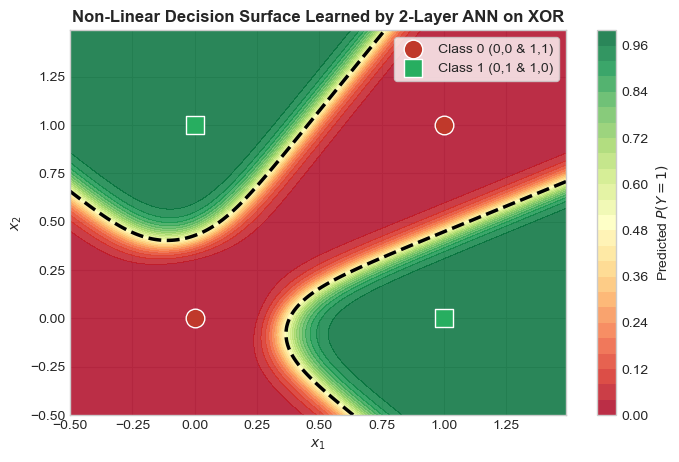

In [3]:
# Visualizing the Non-Linear Decision Surface Learned on XOR
h = 0.01
xx, yy = np.meshgrid(np.arange(-0.5, 1.5, h), np.arange(-0.5, 1.5, h))
grid = np.c_[xx.ravel(), yy.ravel()]
Z_grid = nn_xor.forward(grid).reshape(xx.shape)

plt.figure(figsize=(8, 5))
contour = plt.contourf(xx, yy, Z_grid, levels=30, cmap='RdYlGn', alpha=0.85)
plt.colorbar(contour, label='Predicted $P(Y=1)$')
plt.contour(xx, yy, Z_grid, levels=[0.5], colors='black', linewidths=2.5, linestyles='--')

plt.scatter(X_xor[y_xor == 0, 0], X_xor[y_xor == 0, 1], color='#c0392b', s=180, edgecolors='white', label='Class 0 (0,0 & 1,1)')
plt.scatter(X_xor[y_xor == 1, 0], X_xor[y_xor == 1, 1], color='#27ae60', s=180, marker='s', edgecolors='white', label='Class 1 (0,1 & 1,0)')
plt.title('Non-Linear Decision Surface Learned by 2-Layer ANN on XOR', fontweight='bold')
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.legend(frameon=True)
plt.show()


## 2. Hands-On Case Study: Iris Species Classification
We contrast the single-layer linear **Perceptron** against a **Multi-Layer ANN** on the classic Iris dataset from `../data/Iris.csv`.


In [4]:
# Ingestion from data folder
iris_path = os.path.join("..", "data", "Iris.csv")
if not os.path.exists(iris_path):
    iris_path = os.path.join("data", "Iris.csv")

df = pd.read_csv(iris_path)
print(f"Loaded Iris dataset: {df.shape}")

X = df.drop(columns=[c for c in ['Species', 'Id'] if c in df.columns])
y_raw = df['Species']

encoder = LabelEncoder()
y_int = encoder.fit_transform(y_raw)
class_names = list(encoder.classes_)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_int, test_size=0.20, random_state=SEED, stratify=y_int
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# Model 1: Linear Perceptron
percep = Perceptron(max_iter=1000, random_state=SEED).fit(X_train_scaled, y_train)
y_pred_percep = percep.predict(X_test_scaled)
acc_percep = accuracy_score(y_test, y_pred_percep)

# Model 2: Multi-Layer ANN (MLPClassifier with 16 and 8 hidden neurons)
ann = MLPClassifier(hidden_layer_sizes=(16, 8), activation='relu', solver='adam', max_iter=300, random_state=SEED)
ann.fit(X_train_scaled, y_train)
y_pred_ann = ann.predict(X_test_scaled)
acc_ann = accuracy_score(y_test, y_pred_ann)

print(f"Linear Perceptron Test Accuracy: {acc_percep:.2%}")
print(f"Multi-Layer ANN Test Accuracy:   {acc_ann:.2%}")


Loaded Iris dataset: (150, 6)


Linear Perceptron Test Accuracy: 86.67%
Multi-Layer ANN Test Accuracy:   93.33%


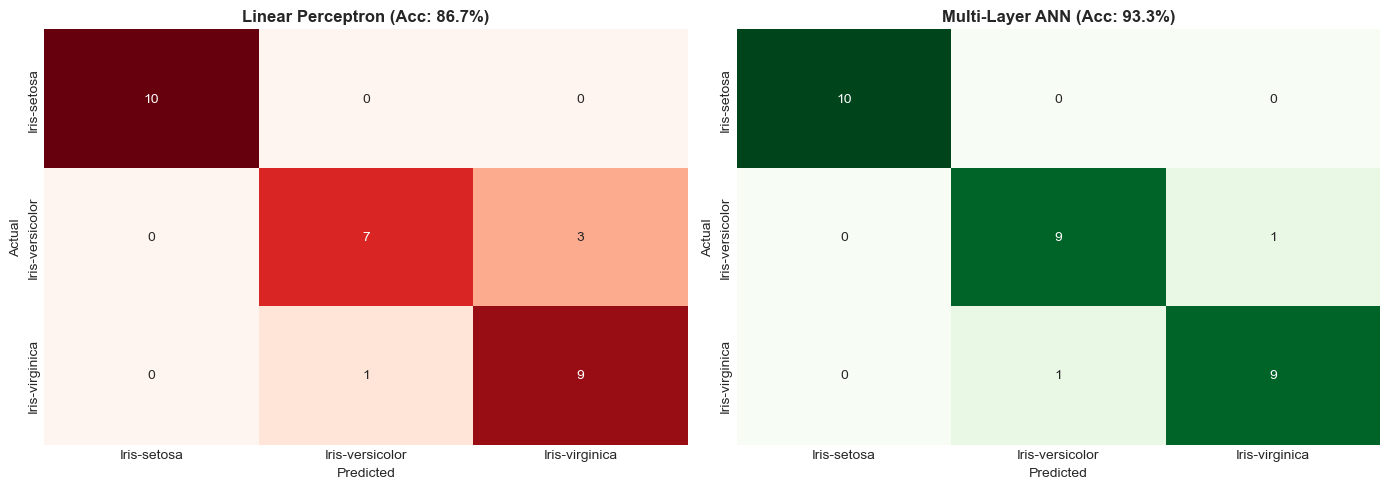

In [5]:
# Side-by-side Confusion Matrix comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

cm_p = confusion_matrix(y_test, y_pred_percep)
sns.heatmap(cm_p, annot=True, fmt='d', cmap='Reds', ax=ax1, cbar=False, xticklabels=class_names, yticklabels=class_names)
ax1.set_title(f'Linear Perceptron (Acc: {acc_percep:.1%})', fontweight='bold')
ax1.set_xlabel('Predicted')
ax1.set_ylabel('Actual')

cm_a = confusion_matrix(y_test, y_pred_ann)
sns.heatmap(cm_a, annot=True, fmt='d', cmap='Greens', ax=ax2, cbar=False, xticklabels=class_names, yticklabels=class_names)
ax2.set_title(f'Multi-Layer ANN (Acc: {acc_ann:.1%})', fontweight='bold')
ax2.set_xlabel('Predicted')
ax2.set_ylabel('Actual')

plt.tight_layout()
plt.show()
